# Atividade 12 — Exploração complementar com agrupamento
## SmartShop AI — Segmentação comportamental de clientes

**Pergunta investigada:** existem perfis de clientes com comportamentos de compra diferentes, e esses perfis se relacionam com a recompra futura?

Esta análise complementa, mas não substitui, o classificador supervisionado do projeto. O agrupamento é construído somente com compras anteriores à data de corte; a recompra no período futuro é usada depois para interpretar os grupos, não para formá-los.

**Caminho escolhido:** A — agrupamento com K-means. O dataset tabular tem milhares de clientes e características de comportamento que permitem procurar perfis sem rótulos prévios.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Ajuste o caminho se o CSV estiver em outra pasta.
df = pd.read_csv("dados_tratados.csv")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print("Dimensões da base tratada:", df.shape)
print("Período:", df["InvoiceDate"].min(), "até", df["InvoiceDate"].max())
print("Clientes identificados:", df["CustomerID"].nunique())

Dimensões da base tratada: (392692, 8)
Período: 2010-12-01 08:26:00 até 2011-12-09 12:50:00
Clientes identificados: 4338


## 1. Data de corte e criação das características

Para manter a lógica temporal já usada no projeto, o corte corresponde ao percentil 80 das datas. As características são calculadas somente com registros até esse corte. A presença de um cliente no período posterior é usada como indicador de recompra futura, apenas para a interpretação posterior.

`CustomerID` é um identificador: não entra no K-means.

In [2]:
data_corte = df["InvoiceDate"].quantile(0.80)
passado = df[df["InvoiceDate"] <= data_corte].copy()
futuro = df[df["InvoiceDate"] > data_corte].copy()

clientes = passado.groupby("CustomerID").agg(
    QuantidadeTotal=("Quantity", "sum"),
    PrecoMedio=("UnitPrice", "mean"),
    QuantidadePedidos=("InvoiceNo", "nunique"),
    UltimaCompra=("InvoiceDate", "max"),
    Pais=("Country", "first")
).reset_index()

clientes["Recencia"] = (data_corte - clientes["UltimaCompra"]).dt.days
clientes["RecomprouFuturo"] = clientes["CustomerID"].isin(
    futuro["CustomerID"].dropna().unique()
).astype(int)

print("Data de corte:", data_corte)
print("Registros anteriores:", len(passado))
print("Registros posteriores:", len(futuro))
print("Clientes para segmentação:", len(clientes))
print("Distribuição de recompra futura (0=não, 1=sim):")
print(clientes["RecomprouFuturo"].value_counts().sort_index())

Data de corte: 2011-11-01 15:55:00
Registros anteriores: 314183
Registros posteriores: 78509
Clientes para segmentação: 3985
Distribuição de recompra futura (0=não, 1=sim):
RecomprouFuturo
0    2455
1    1530
Name: count, dtype: int64


## 2. Variáveis e preparação

Foram escolhidas quatro características interpretáveis: quantidade total comprada, preço médio, número de pedidos e recência. `CustomerID`, `Pais`, datas brutas e a variável `RecomprouFuturo` foram excluídos da formação dos grupos. País é categórico e não foi convertido artificialmente em uma distância numérica.

Quantidade, preço médio e número de pedidos apresentam assimetria e valores extremos; por isso, aplica-se `log1p` nessas três variáveis. Em seguida, todas as quatro características são padronizadas com `StandardScaler`, requisito importante porque K-means usa distâncias.

In [3]:
variaveis = ["QuantidadeTotal", "PrecoMedio", "QuantidadePedidos", "Recencia"]
X = clientes[variaveis].copy()

for coluna in ["QuantidadeTotal", "PrecoMedio", "QuantidadePedidos"]:
    X[coluna] = np.log1p(X[coluna])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Variáveis utilizadas:", variaveis)
print("Identificadores removidos das variáveis:", "CustomerID" not in variaveis)
print("Média aproximada após padronização:", np.round(X_scaled.mean(axis=0), 3))
print("Desvio-padrão aproximado após padronização:", np.round(X_scaled.std(axis=0), 3))

Variáveis utilizadas: ['QuantidadeTotal', 'PrecoMedio', 'QuantidadePedidos', 'Recencia']
Identificadores removidos das variáveis: True
Média aproximada após padronização: [-0. -0.  0.  0.]
Desvio-padrão aproximado após padronização: [1. 1. 1. 1.]


## 3. Escolha do número de grupos

Comparamos k entre 2 e 6 usando o método do cotovelo (inércia) e o coeficiente de silhueta. A silhueta mede o quanto os pontos tendem a estar mais próximos do próprio grupo do que dos outros; valores maiores são preferíveis, mas não substituem a interpretação de negócio.

A decisão final considera as duas evidências e a utilidade de perfis interpretáveis.

,k,Inercia,Silhueta
0,2,10528.668,0.312
1,3,8088.826,0.300
2,4,6881.899,0.307
3,5,6062.985,0.260
4,6,5355.002,0.257


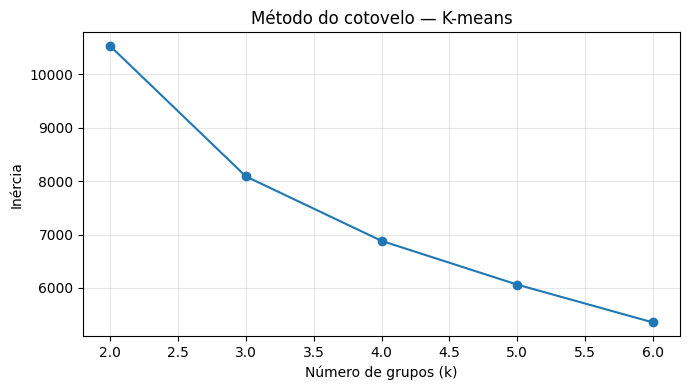

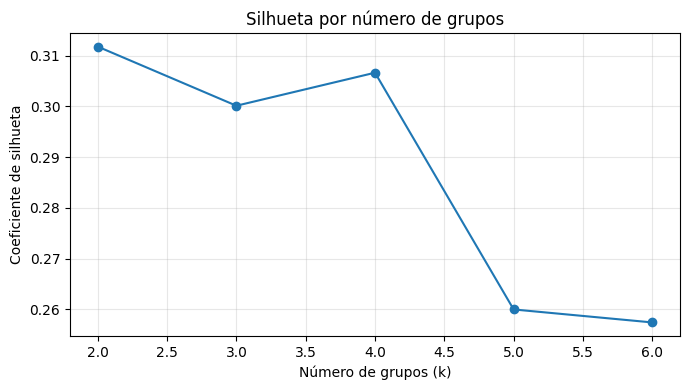

In [4]:
resultados_k = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    grupos = km.fit_predict(X_scaled)
    resultados_k.append({
        "k": k,
        "Inercia": km.inertia_,
        "Silhueta": silhouette_score(X_scaled, grupos)
    })

avaliacoes = pd.DataFrame(resultados_k)
display(avaliacoes.round(3))

plt.figure(figsize=(7, 4))
plt.plot(avaliacoes["k"], avaliacoes["Inercia"], marker="o")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inércia")
plt.title("Método do cotovelo — K-means")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(avaliacoes["k"], avaliacoes["Silhueta"], marker="o")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Coeficiente de silhueta")
plt.title("Silhueta por número de grupos")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Critério adotado:** k=4 será usado como solução exploratória porque mantém quatro perfis que podem ser interpretados no contexto do negócio, com silhueta comparável à melhor solução observada. A silhueta máxima entre os k testados ocorre em k=2; portanto, k=4 não deve ser tratado como verdade única. A comparação de perfis e a limitação dessa escolha serão explicitadas.

In [5]:
k_final = 4
modelo_kmeans = KMeans(n_clusters=k_final, random_state=42, n_init=10)
clientes["Grupo"] = modelo_kmeans.fit_predict(X_scaled)

perfis = clientes.groupby("Grupo").agg(
    Clientes=("CustomerID", "size"),
    QuantidadeTotal_media=("QuantidadeTotal", "mean"),
    PrecoMedio_medio=("PrecoMedio", "mean"),
    Pedidos_medio=("QuantidadePedidos", "mean"),
    Recencia_media=("Recencia", "mean"),
    Taxa_recompra=("RecomprouFuturo", "mean")
).reset_index()
perfis["Percentual_base"] = perfis["Clientes"] / len(clientes) * 100
perfis["Taxa_recompra_pct"] = perfis["Taxa_recompra"] * 100

def nomear_perfil(linha):
    if linha["Pedidos_medio"] >= 7 and linha["Recencia_media"] < 60:
        return "Clientes frequentes e recentes"
    if linha["PrecoMedio_medio"] > 10:
        return "Compradores de itens de maior preço médio"
    if linha["Recencia_media"] > 150:
        return "Clientes há mais tempo sem comprar"
    return "Clientes de compras ocasionais"

perfis["Nome_descritivo"] = perfis.apply(nomear_perfil, axis=1)
mapa_nomes = dict(zip(perfis["Grupo"], perfis["Nome_descritivo"]))
clientes["Perfil"] = clientes["Grupo"].map(mapa_nomes)

display(perfis[["Grupo","Nome_descritivo","Clientes","Percentual_base",
                "QuantidadeTotal_media","PrecoMedio_medio","Pedidos_medio",
                "Recencia_media","Taxa_recompra_pct"]].round(2))

,Grupo,Nome_descritivo,Clientes,Percentual_base,QuantidadeTotal_media,PrecoMedio_medio,Pedidos_medio,Recencia_media,Taxa_recompra_pct
0,0,Clientes há mais tempo sem comprar,916,22.99,215.31,3.20,1.35,233.12,19.54
1,1,Clientes frequentes e recentes,1021,25.62,3147.62,3.10,9.62,32.99,69.44
2,2,Compradores de itens de maior preço médio,290,7.28,199.86,25.21,1.78,126.87,22.76
3,3,Clientes de compras ocasionais,1758,44.12,424.82,2.87,2.05,49.77,32.76


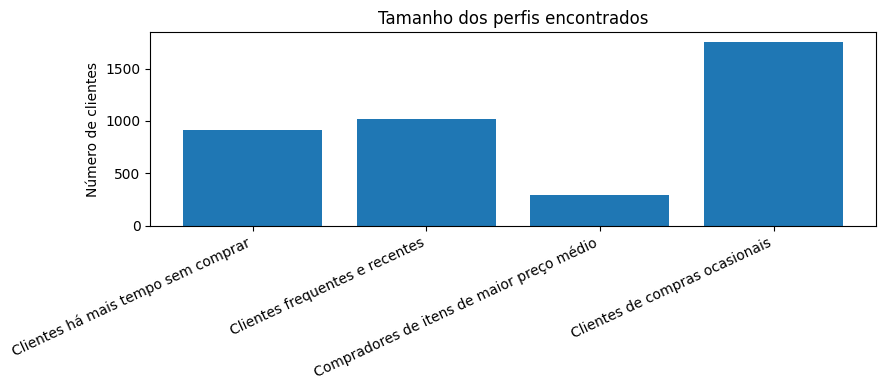

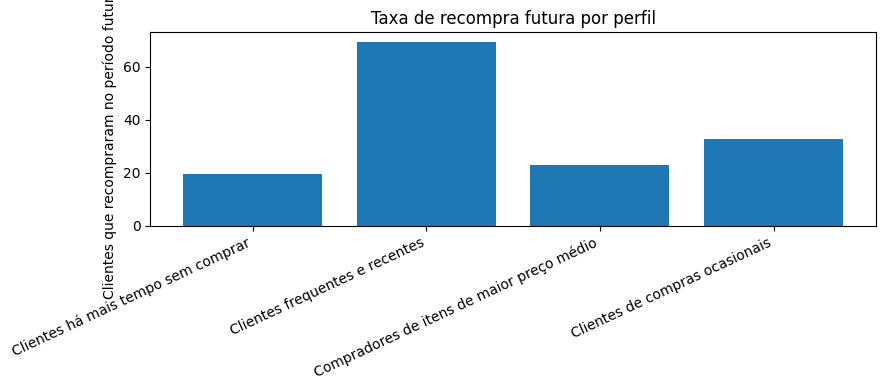

In [6]:
plt.figure(figsize=(9, 4))
plt.bar(perfis["Nome_descritivo"], perfis["Clientes"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("Número de clientes")
plt.title("Tamanho dos perfis encontrados")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(perfis["Nome_descritivo"], perfis["Taxa_recompra_pct"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("Clientes que recompraram no período futuro (%)")
plt.title("Taxa de recompra futura por perfil")
plt.tight_layout()
plt.show()

## 4. Interpretação dos resultados

Os nomes dos perfis são descrições simplificadas baseadas nas médias observadas, não rótulos produzidos pelo algoritmo. A tabela de perfis mostra diferenças em volume comprado, preço médio, frequência e recência. O cruzamento com a recompra futura é uma leitura posterior e não foi usado para formar os grupos.

Ao interpretar, considere o tamanho de cada grupo, se ele se distingue em mais de uma variável e se uma ação comercial diferente seria plausível. A taxa de recompra é uma associação descritiva; não prova que o grupo causa a recompra nem garante que uma campanha específica funcionará.

In [7]:
# Tabela comparando os perfis com a média geral da base
media_geral = clientes[variaveis].mean()
tabela_comparacao = perfis[["Grupo","Nome_descritivo","Clientes","Percentual_base",
                           "QuantidadeTotal_media","PrecoMedio_medio","Pedidos_medio",
                           "Recencia_media","Taxa_recompra_pct"]].copy()
tabela_comparacao["QuantidadeTotal_media_vs_geral"] = tabela_comparacao["QuantidadeTotal_media"] / media_geral["QuantidadeTotal"]
tabela_comparacao["PrecoMedio_vs_geral"] = tabela_comparacao["PrecoMedio_medio"] / media_geral["PrecoMedio"]
tabela_comparacao["Pedidos_vs_geral"] = tabela_comparacao["Pedidos_medio"] / media_geral["QuantidadePedidos"]
tabela_comparacao["Recencia_vs_geral_dias"] = tabela_comparacao["Recencia_media"] - media_geral["Recencia"]
display(tabela_comparacao.round(2))

print("Médias gerais da base:")
display(media_geral.to_frame("Média geral").round(2))

,Grupo,Nome_descritivo,Clientes,Percentual_base,QuantidadeTotal_media,PrecoMedio_medio,Pedidos_medio,Recencia_media,Taxa_recompra_pct,QuantidadeTotal_media_vs_geral,PrecoMedio_vs_geral,Pedidos_vs_geral,Recencia_vs_geral_dias
0,0,Clientes há mais tempo sem comprar,916,22.99,215.31,3.20,1.35,233.12,19.54,0.20,0.69,0.35,139.89
1,1,Clientes frequentes e recentes,1021,25.62,3147.62,3.10,9.62,32.99,69.44,2.98,0.67,2.53,-60.24
2,2,Compradores de itens de maior preço médio,290,7.28,199.86,25.21,1.78,126.87,22.76,0.19,5.45,0.47,33.64
3,3,Clientes de compras ocasionais,1758,44.12,424.82,2.87,2.05,49.77,32.76,0.40,0.62,0.54,-43.45


Médias gerais da base:


,Média geral
QuantidadeTotal,1057.90
PrecoMedio,4.63
QuantidadePedidos,3.81
Recencia,93.23


## 5. Avaliação honesta do valor para o SmartShop AI

A segmentação agrega valor exploratório porque resume padrões diferentes de comportamento e mostra que a taxa de recompra futura varia entre os perfis. Isso pode ajudar a formular hipóteses para estratégias de relacionamento e para futuras avaliações do sistema.

Entretanto, a análise não é ainda um mecanismo de recomendação de produtos. Ela não prova qual produto deve ser recomendado nem demonstra que usar os grupos aumenta vendas. O valor é complementar: oferece perfis comportamentais para investigação posterior e uma forma de estudar diferenças que uma classificação binária sozinha não explica.

## 6. Limitações

- K-means depende da escala, das variáveis selecionadas e do número de grupos; outra escolha pode produzir perfis diferentes.
- A silhueta foi modesta, e k=2 apresentou valor ligeiramente maior que k=4; a solução de quatro grupos foi escolhida pela interpretabilidade exploratória, não por superioridade matemática absoluta.
- A transformação logarítmica reduz o peso de valores extremos, mas não elimina todos os seus efeitos.
- O preço médio pode ser influenciado por produtos muito caros e não equivale ao gasto total do cliente.
- O indicador de recompra apenas verifica presença do cliente no período futuro; não mede valor gasto, quantidade de produtos ou satisfação.
- A base cobre um período limitado de 2010–2011, portanto os padrões podem não representar clientes atuais.
- As diferenças observadas são descritivas e não demonstram causalidade.
- Os nomes dos grupos são interpretações humanas simplificadas e devem ser revistos se as médias ou a composição mudarem.

## 7. Conclusão

O agrupamento encontrou quatro perfis exploratórios com diferenças de frequência, recência, volume e preço médio. A taxa de recompra futura também variou entre eles, o que sugere que a segmentação pode complementar o estudo do comportamento dos clientes. O resultado deve ser usado como hipótese para experimentos futuros, não como prova de que uma recomendação específica será eficaz.

**Produção e uso de IA:** ChatGPT foi utilizado como apoio à organização do notebook e à redação inicial. O código, as saídas e a interpretação precisam ser conferidos pelo estudante antes da entrega; a responsabilidade por compreender e validar os resultados é do autor.